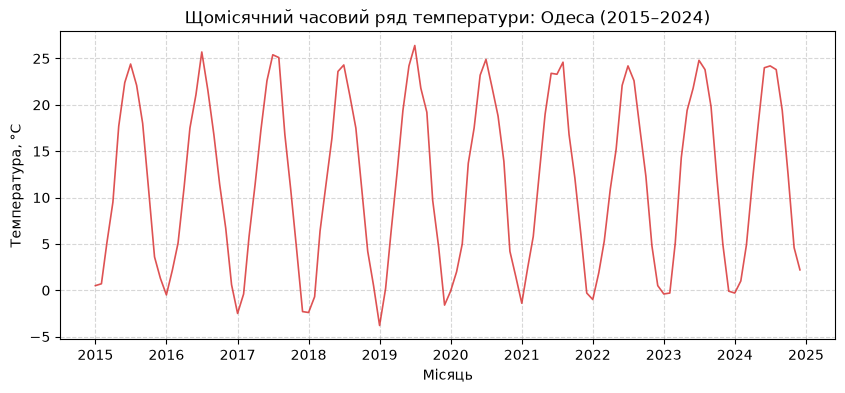

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

np.random.seed(3)
base_temp = 11.5
amplitude = 13.0
trend_per_year = 0.05
noise_scale = 1.1
city = "Одеса"
n_years = 10

dates = pd.date_range(start="2015-01-01", periods=n_years * 12, freq="MS")
month = dates.month
years_elapsed = (dates.year - dates.year[0]) + (dates.month - 1) / 12

seasonal = amplitude * np.cos((month - 7) / 12 * 2 * np.pi)
trend = trend_per_year * years_elapsed
noise = np.random.normal(0, noise_scale, len(dates))
temp = np.round(base_temp + trend + seasonal + noise, 1)

climate_ts = pd.Series(temp, index=dates, name="температура")

# Побудова графіку
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    climate_ts.index,
    climate_ts.values,
    color="tab:red",
    alpha=0.8,
    linewidth=1.2,
)
ax.set_xlabel("Місяць")
ax.set_ylabel("Температура, °C")
ax.set_title(f"Щомісячний часовий ряд температури: {city} (2015–2024)")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()

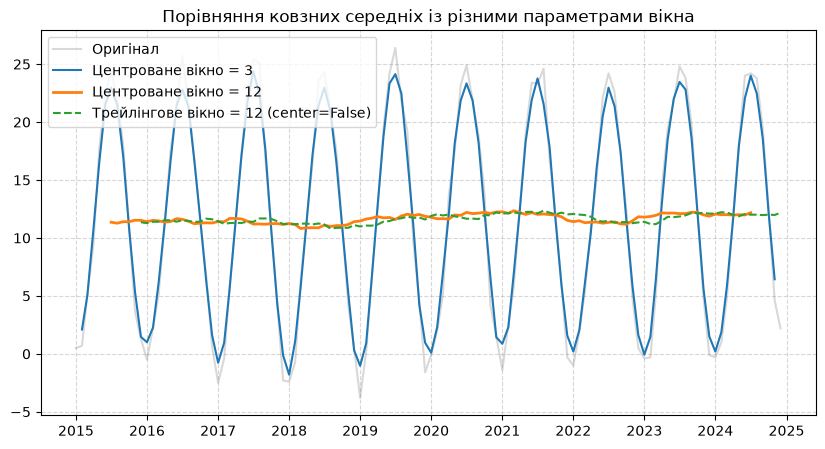

In [2]:
ma3 = climate_ts.rolling(window=3, center=True).mean()
ma12_centered = climate_ts.rolling(window=12, center=True).mean()
ma12_trailing = climate_ts.rolling(window=12, center=False).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    climate_ts.index,
    climate_ts.values,
    alpha=0.3,
    color="gray",
    label="Оригінал",
)
ax.plot(
    climate_ts.index, ma3.values, color="tab:blue", label="Центроване вікно = 3"
)
ax.plot(
    climate_ts.index,
    ma12_centered.values,
    color="tab:orange",
    linewidth=2,
    label="Центроване вікно = 12",
)
ax.plot(
    climate_ts.index,
    ma12_trailing.values,
    color="tab:green",
    linestyle="--",
    label="Трейлінгове вікно = 12 (center=False)",
)
ax.legend()
ax.set_title("Порівняння ковзних середніх із різними параметрами вікна")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()

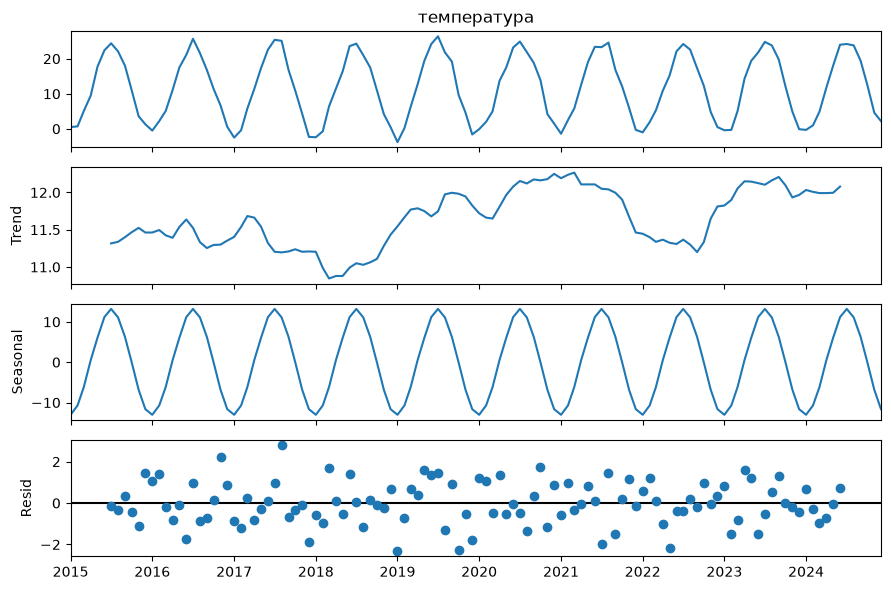

Стандартне відхилення залишку (resid): 1.04


In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(climate_ts, model="additive", period=12)
fig = decomposition.plot()
fig.set_size_inches(9, 6)
plt.tight_layout()
plt.show()

print("Стандартне відхилення залишку (resid):", round(decomposition.resid.dropna().std(), 2))

Прогноз на 12 місяців уперед:
2025-01-01    -1.0
2025-02-01     1.4
2025-03-01     5.9
2025-04-01    12.6
2025-05-01    18.2
2025-06-01    23.3
2025-07-01    25.3
2025-08-01    23.2
2025-09-01    18.4
2025-10-01    12.1
2025-11-01     5.3
2025-12-01     0.5
Freq: MS, dtype: float64


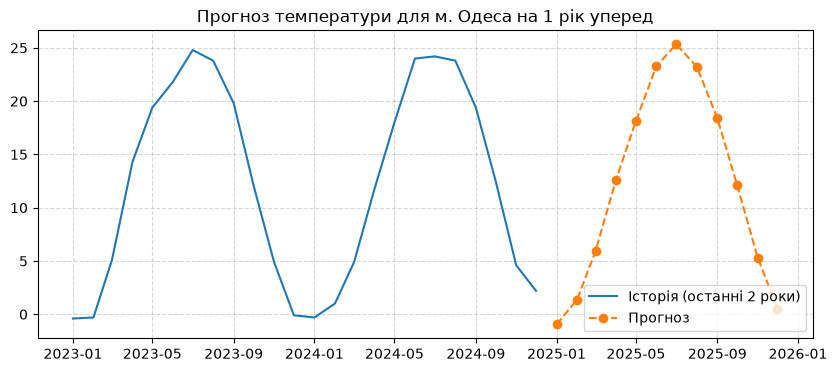

In [4]:
from scipy.stats import linregress

t = np.arange(len(climate_ts))
known = decomposition.trend.notna().values
fit = linregress(t[known], decomposition.trend[known])

n_ahead = 12
t_future = np.arange(len(climate_ts), len(climate_ts) + n_ahead)
trend_forecast = fit.intercept + fit.slope * t_future

seasonal_by_month = decomposition.seasonal.groupby(decomposition.seasonal.index.month).mean()
future_dates = pd.date_range(climate_ts.index[-1] + pd.offsets.MonthBegin(1), periods=n_ahead, freq="MS")
seasonal_forecast = seasonal_by_month.reindex(future_dates.month).values

forecast = pd.Series(trend_forecast + seasonal_forecast, index=future_dates)
print("Прогноз на 12 місяців уперед:")
print(forecast.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(climate_ts.index[-24:], climate_ts.values[-24:], label="Історія (останні 2 роки)", color="tab:blue")
ax.plot(forecast.index, forecast.values, label="Прогноз", color="tab:orange", marker="o", linestyle="--")
ax.legend()
ax.set_title("Прогноз температури для м. Одеса на 1 рік уперед")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [5]:
deseason = climate_ts - decomposition.seasonal
t_years = np.arange(len(climate_ts)) / 12
trend_test = linregress(t_years, deseason.values)

print(f"Нахил: {trend_test.slope:.4f} °C/рік")
print(f"StdErr: {trend_test.stderr:.4f}")
print(f"p-value: {trend_test.pvalue:.4e}")

ci_lower = trend_test.slope - 1.96 * trend_test.stderr
ci_upper = trend_test.slope + 1.96 * trend_test.stderr
print(f"95% довірчий інтервал: [{ci_lower:.4f}, {ci_upper:.4f}]")

Нахил: 0.0904 °C/рік
StdErr: 0.0346
p-value: 1.0157e-02
95% довірчий інтервал: [0.0226, 0.1582]


### Контрольні питання та відповіді

#### 1. Чому часовий ряд не можна аналізувати тими самими методами, що звичайну незалежну вибірку (Лекції 12–16), і що саме в даних це порушує?

* **Відповідь:** У класичній статистиці (для незалежних вибірок) обов’язковою умовою є взаємна незалежність спостережень (відсутність зв'язку між сусідніми елементами). У часових рядах сусідні точки тісно пов'язані між собою через тренд, сезонність та інерційність процесів (це явище називається **автокореляцією**). Пряме застосування стандартних тестів без урахування часової структури порушує базові припущення моделей, що призводить до хибних оцінок похибок, завищеної статистичної значущості (надто малого `p-value`) та неправильних висновків.

---

#### 2. Чому надто мале й надто велике вікно ковзного середнього — обидва проблема, і як розмір вікна варто узгоджувати з періодом сезонності?

* **Відповідь:**
* **Занадто мале вікно** не здатне повністю прибрати високочастотний шум та залишки сезонних хвиль, через що оцінка тренду залишається надто «шумною».
* **Занадто велике вікно** надмірно згладжує ряд, стирає важливі локальні зміни, створює величезні пропуски на кінцях вибірки та спотворює реальну динаміку процесу.
* **Узгодження з сезонністю:** Розмір вікна обов’язково має бути кратним періоду сезонності (наприклад, для місячних даних із річним циклом вікно дорівнює 12). Це забезпечує повне «перекриття» одного повного циклу коливань, завдяки чому додатні та від'ємні сезонні відхилення симетрично компенсують одне одного і повністю зникають із результату згладжування.



---

#### 3. У чому різниця між трейлінговим (`center=False`) і центрованим (`center=True`) ковзним середнім, і чому центроване недоступне «в реальному часі»?

* **Відповідь:**
* **Трейлінгове (зміщене назад) середнє** розраховується на основі поточного та попередніх періодів. Його головний недолік — **систематичний лаг (часовий зсув)** праворуч: крива явно відстає від реальних циклічних піків і спадів приблизно на половину ширини вікна.
* **Центроване середнє** симетрично охоплює період навколо цільової точки (попередні, поточні та майбутні місяці), що повністю усуває часовий зсув.
* **Чому недоступне в реальному часі:** Оскільки центроване середнє використовує дані, які лежать *у майбутньому* відносно поточного моменту часу, його фізично неможливо розрахувати «на льоту» для найсвіжіших (останніх) місячних спостережень без звернення до ще не насталих подій.



---

#### 4. Чому саме `p-value` нахилу тренду, а не лише знак `slope`, визначає наявність тренду, а не випадкового шуму?

* **Відповідь:** Сам по собі додатний чи від'ємний знак коефіцієнта нахилу (`slope > 0`) свідчить лише про те, що на конкретній скінченній вибірці лінія піднімається вгору. Проте потужний випадковий шум (особливо у кліматичних чи економічних рядах) здатний випадково сформувати «видимість» тренду на коротких або середніх прорізах часу.
* Саме **`p-value`** та **довірчий інтервал** дозволяють перевірити нульову гіпотезу ($H_0$: істинний нахил дорівнює нулю, а зміна зумовлена виключно шумом). Лише низьке значення `p-value` (зазвичай $< 0.05$) дає статистичне право відхилити $H_0$ й стверджувати, що виявлений тренд є значущим, а не випадковою флуктуацією.